# CardioIA Fase 4: Parte 2, CNN simples treinada do zero

**Curso:** Inteligência Artificial, FIAP, turma 2TIAOR, Fase 4, Cap 1 (Visão Computacional na Clínica)
**Autor:** Silvio Prestes Guerreiro Junior, RM 567958

> **Aviso:** protótipo acadêmico, sem validade diagnóstica. Nenhum resultado deste notebook deve orientar conduta clínica.

## Objetivo

Treinar uma rede neural convolucional simples, sem pesos pré-treinados, para classificar radiografias de tórax em **Cardiomegalia** ou **Sem achado**, e avaliá-la no conjunto de teste com acurácia, matriz de confusão, precisão, recall e F1-score.

Os dados vêm do notebook `01_preprocessamento.ipynb`: 5.552 imagens 224 x 224, divididas por paciente em treino, validação e teste. Este modelo serve de referência para a comparação com o Transfer Learning do notebook `03`.

## 1. Configuração e leitura dos dados

In [1]:
import os, sys, json, time, random
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.metrics import (confusion_matrix, classification_report, accuracy_score, precision_score,
                             recall_score, f1_score, roc_auc_score, roc_curve)

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.keras.utils.set_random_seed(SEED)

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DIR_PROC, DIR_PRINT, DIR_MOD = RAIZ / "data" / "processed", RAIZ / "prints", RAIZ / "models"
DIR_MOD.mkdir(exist_ok=True)

IMG_SIZE, BATCH = 224, 32
CLASSES = ["sem_achado", "cardiomegalia"]          # 0 = negativa, 1 = positiva
print("TensorFlow", tf.__version__, "| GPU:", tf.config.list_physical_devices("GPU") or "nenhuma (treino em CPU)")

TensorFlow 2.21.0 | GPU: nenhuma (treino em CPU)


In [2]:
# Mesmos geradores definidos na Parte 1: normalização em todos, aumento de dados só no treino
gen_treino = ImageDataGenerator(rescale=1./255, rotation_range=7, width_shift_range=0.05,
                                height_shift_range=0.05, zoom_range=0.10, fill_mode="constant", cval=0)
gen_aval = ImageDataGenerator(rescale=1./255)
kw = dict(target_size=(IMG_SIZE, IMG_SIZE), color_mode="rgb", class_mode="binary", classes=CLASSES, batch_size=BATCH, seed=SEED)
treino = gen_treino.flow_from_directory(DIR_PROC / "train", shuffle=True, **kw)
val    = gen_aval.flow_from_directory(DIR_PROC / "val", shuffle=False, **kw)
teste  = gen_aval.flow_from_directory(DIR_PROC / "test", shuffle=False, **kw)

Found 3928 images belonging to 2 classes.


Found 805 images belonging to 2 classes.


Found 819 images belonging to 2 classes.


## 2. Arquitetura

A rede segue o padrão visto no Cap 11 (blocos de convolução com ReLU e max pooling, seguidos de camadas densas), ampliado para imagens de 224 x 224:

- quatro blocos `Conv2D 3x3 + ReLU + MaxPooling 2x2`, com 32, 64, 128 e 128 filtros. Cada bloco reduz a resolução pela metade (224, 112, 56, 28, 14) e aumenta a abstração das características;
- `Flatten`, `Dropout` de 50% para reduzir overfitting, uma camada densa de 128 neurônios e a saída;
- saída com **um neurônio sigmoide**, que devolve a probabilidade de Cardiomegalia. Em problema binário isso equivale à saída softmax de dois neurônios usada em aula, com metade dos parâmetros na última camada. A função de perda correspondente é a entropia cruzada binária.

In [3]:
def criar_cnn():
    m = models.Sequential([
        layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),
        layers.Conv2D(32, (3, 3), activation="relu", padding="same"), layers.MaxPooling2D((2, 2)),
        layers.Conv2D(64, (3, 3), activation="relu", padding="same"), layers.MaxPooling2D((2, 2)),
        layers.Conv2D(128, (3, 3), activation="relu", padding="same"), layers.MaxPooling2D((2, 2)),
        layers.Conv2D(128, (3, 3), activation="relu", padding="same"), layers.MaxPooling2D((2, 2)),
        layers.Flatten(),
        layers.Dropout(0.5),
        layers.Dense(128, activation="relu"),
        layers.Dense(1, activation="sigmoid"),
    ], name="cnn_do_zero")
    m.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3), loss="binary_crossentropy",
              metrics=["accuracy", tf.keras.metrics.AUC(name="auc"), tf.keras.metrics.Recall(name="recall")])
    return m

modelo = criar_cnn()
modelo.summary()

Model: "cnn_do_zero"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,452,353 (13.17 MB)

 Trainable params: 3,452,353 (13.17 MB)

 Non-trainable params: 0 (0.00 B)

## 3. Treinamento

- **Otimizador:** Adam, taxa de aprendizado inicial de 0,001.
- **Parada antecipada (early stopping):** o treino para se a perda de validação não melhorar por 7 épocas, e os pesos da melhor época são restaurados. Assim o número de épocas não é escolhido à mão.
- **Redução da taxa de aprendizado:** cai pela metade após 3 épocas sem melhora na validação.
- O conjunto de teste não participa de nenhuma decisão do treino.

In [4]:
cbs = [
    callbacks.EarlyStopping(monitor="val_loss", patience=7, restore_best_weights=True, verbose=1),
    callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-5, verbose=1),
    callbacks.ModelCheckpoint(DIR_MOD / "cnn_do_zero.keras", monitor="val_loss", save_best_only=True),
]
t0 = time.time()
hist = modelo.fit(treino, validation_data=val, epochs=40, callbacks=cbs, verbose=2)
tempo_treino = time.time() - t0
h = pd.DataFrame(hist.history); h.index += 1
melhor = int(h.val_loss.idxmin())
print(f"\nTempo de treino: {tempo_treino/60:.1f} min | épocas executadas: {len(h)} | melhor época (val_loss): {melhor}")
h.to_csv(RAIZ / "data" / "historico_cnn_do_zero.csv", index_label="epoca")

Epoch 1/40


123/123 - 53s - 433ms/step - accuracy: 0.6092 - auc: 0.6593 - loss: 0.6538 - recall: 0.5919 - val_accuracy: 0.7143 - val_auc: 0.7832 - val_loss: 0.6046 - val_recall: 0.6452 - learning_rate: 0.0010


Epoch 2/40


123/123 - 52s - 423ms/step - accuracy: 0.6841 - auc: 0.7514 - loss: 0.5938 - recall: 0.7149 - val_accuracy: 0.6932 - val_auc: 0.7599 - val_loss: 0.5952 - val_recall: 0.6967 - learning_rate: 0.0010


Epoch 3/40


123/123 - 51s - 416ms/step - accuracy: 0.6983 - auc: 0.7645 - loss: 0.5814 - recall: 0.7003 - val_accuracy: 0.7366 - val_auc: 0.8107 - val_loss: 0.5406 - val_recall: 0.7429 - learning_rate: 0.0010


... (75 outputs left out)

Epoch 40/40


123/123 - 49s - 400ms/step - accuracy: 0.8055 - auc: 0.8850 - loss: 0.4266 - recall: 0.8252 - val_accuracy: 0.7851 - val_auc: 0.8700 - val_loss: 0.4490 - val_recall: 0.8021 - learning_rate: 1.2500e-04


Restoring model weights from the end of the best epoch: 39.



Tempo de treino: 33.1 min | épocas executadas: 40 | melhor época (val_loss): 39


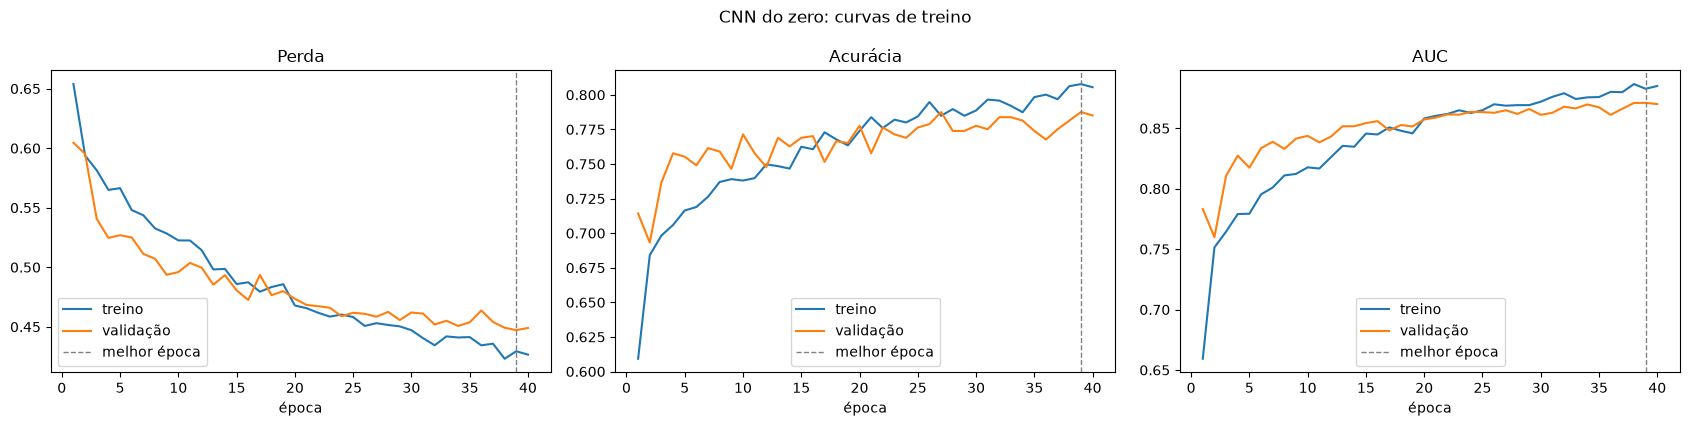

,accuracy,auc,loss,recall,val_accuracy,val_auc,val_loss,val_recall,learning_rate
39,0.8078,0.8827,0.4295,0.8227,0.7876,0.871,0.4472,0.7789,0.0001


In [5]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.3))
for a, (m, t) in zip(ax, [("loss", "Perda"), ("accuracy", "Acurácia"), ("auc", "AUC")]):
    a.plot(h.index, h[m], label="treino"); a.plot(h.index, h["val_" + m], label="validação")
    a.axvline(melhor, color="gray", ls="--", lw=1, label="melhor época"); a.set_title(t); a.set_xlabel("época"); a.legend()
plt.suptitle("CNN do zero: curvas de treino"); plt.tight_layout()
plt.savefig(DIR_PRINT / "06_cnn_curvas_treino.png", dpi=130); plt.show()
h.loc[[melhor]].round(4)

## 4. Avaliação no conjunto de teste

O modelo com os pesos da melhor época de validação é avaliado uma única vez nas 819 imagens de teste, de pacientes que a rede nunca viu. O limiar de decisão padrão é 0,5: probabilidade igual ou acima disso é classificada como Cardiomegalia.

In [6]:
def avaliar(y, p, limiar=0.5):
    yp = (p >= limiar).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, yp).ravel()
    return {"limiar": round(float(limiar), 3), "acuracia": accuracy_score(y, yp), "precisao": precision_score(y, yp),
            "recall": recall_score(y, yp), "f1": f1_score(y, yp), "especificidade": tn / (tn + fp),
            "auc": roc_auc_score(y, p), "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp)}

p_val, y_val = modelo.predict(val, verbose=0).ravel(), val.classes
p_test, y_test = modelo.predict(teste, verbose=0).ravel(), teste.classes

r05 = avaliar(y_test, p_test, 0.5)
print(pd.Series(r05).round(4).to_string())
print("\n", classification_report(y_test, (p_test >= 0.5).astype(int), target_names=CLASSES, digits=4))

limiar              0.5000
acuracia            0.7985
precisao            0.7869
recall              0.8085
f1                  0.7975
especificidade      0.7890
auc                 0.8742
tn                329.0000
fp                 88.0000
fn                 77.0000
tp                325.0000

                precision    recall  f1-score   support

   sem_achado     0.8103    0.7890    0.7995       417
cardiomegalia     0.7869    0.8085    0.7975       402

     accuracy                         0.7985       819
    macro avg     0.7986    0.7987    0.7985       819
 weighted avg     0.7988    0.7985    0.7985       819



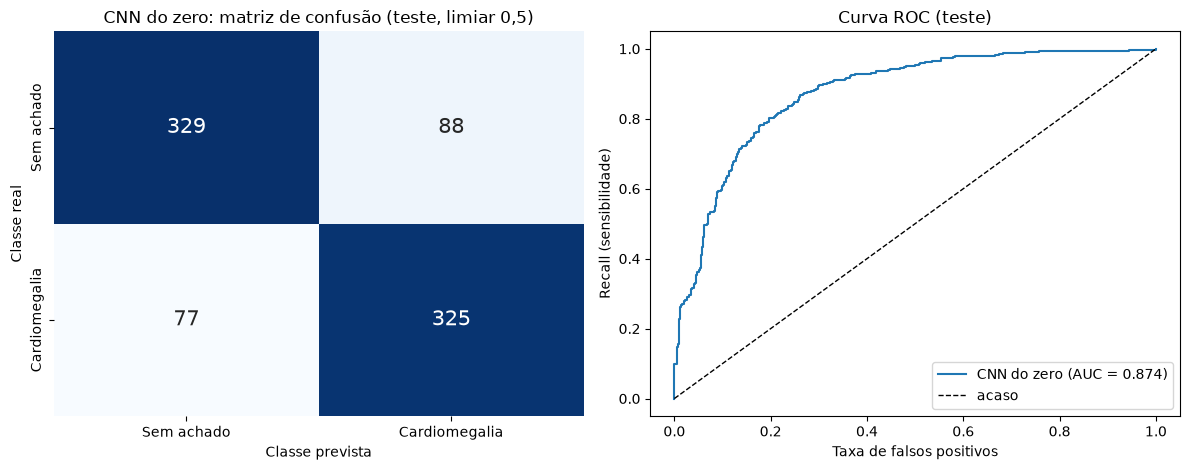

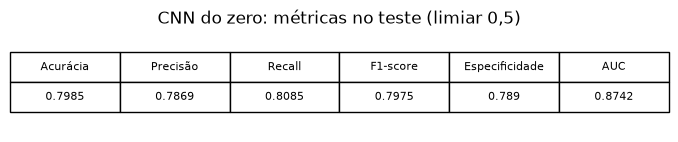

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.8))
cm = confusion_matrix(y_test, (p_test >= 0.5).astype(int))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax[0], annot_kws={"size": 15},
            xticklabels=["Sem achado", "Cardiomegalia"], yticklabels=["Sem achado", "Cardiomegalia"])
ax[0].set_xlabel("Classe prevista"); ax[0].set_ylabel("Classe real"); ax[0].set_title("CNN do zero: matriz de confusão (teste, limiar 0,5)")
fpr, tpr, _ = roc_curve(y_test, p_test)
ax[1].plot(fpr, tpr, label=f"CNN do zero (AUC = {r05['auc']:.3f})"); ax[1].plot([0, 1], [0, 1], "k--", lw=1, label="acaso")
ax[1].set_xlabel("Taxa de falsos positivos"); ax[1].set_ylabel("Recall (sensibilidade)"); ax[1].set_title("Curva ROC (teste)"); ax[1].legend()
plt.tight_layout(); plt.savefig(DIR_PRINT / "07_cnn_matriz_confusao_roc.png", dpi=130); plt.show()

tab = pd.DataFrame([r05])[["acuracia", "precisao", "recall", "f1", "especificidade", "auc"]].round(4)
fig, ax = plt.subplots(figsize=(8.5, 1.3)); ax.axis("off")
t = ax.table(cellText=tab.values, colLabels=["Acurácia", "Precisão", "Recall", "F1-score", "Especificidade", "AUC"], loc="center", cellLoc="center")
t.scale(1, 1.8); ax.set_title("CNN do zero: métricas no teste (limiar 0,5)")
plt.savefig(DIR_PRINT / "08_cnn_metricas.png", dpi=130, bbox_inches="tight"); plt.show()

## 5. O custo do falso negativo e a escolha do limiar

Em triagem clínica os dois erros não custam o mesmo. Um **falso positivo** gera uma revisão desnecessária pelo médico. Um **falso negativo** deixa passar um coração aumentado, e o paciente pode ficar sem investigação. Por isso a acurácia sozinha não basta: o recall (sensibilidade) da classe Cardiomegalia é a métrica que mais importa.

O limiar de 0,5 não é obrigatório. Abaixo, escolhemos **no conjunto de validação** o maior limiar que mantém recall de pelo menos 90% e aplicamos esse limiar, sem reajuste, ao teste. Escolher o limiar olhando o teste seria vazamento.

In [8]:
cand = np.round(np.arange(0.05, 0.96, 0.01), 2)
rec_val = np.array([recall_score(y_val, (p_val >= c).astype(int)) for c in cand])
limiar_sens = float(cand[rec_val >= 0.90].max())
rs = avaliar(y_test, p_test, limiar_sens)
comp = pd.DataFrame([r05, rs], index=["limiar 0,5 (padrão)", f"limiar {limiar_sens:.2f} (recall >= 90% na validação)"])
print("Recall na validação com o limiar escolhido:", round(float(rec_val[cand == limiar_sens][0]), 4))
comp[["acuracia", "precisao", "recall", "f1", "especificidade", "fn", "fp"]].round(4)

Recall na validação com o limiar escolhido: 0.9049


,acuracia,precisao,recall,f1,especificidade,fn,fp
"limiar 0,5 (padrão)",0.7985,0.7869,0.8085,0.7975,0.789,77,88
limiar 0.36 (recall >= 90% na validação),0.7937,0.7432,0.8856,0.8082,0.705,46,123


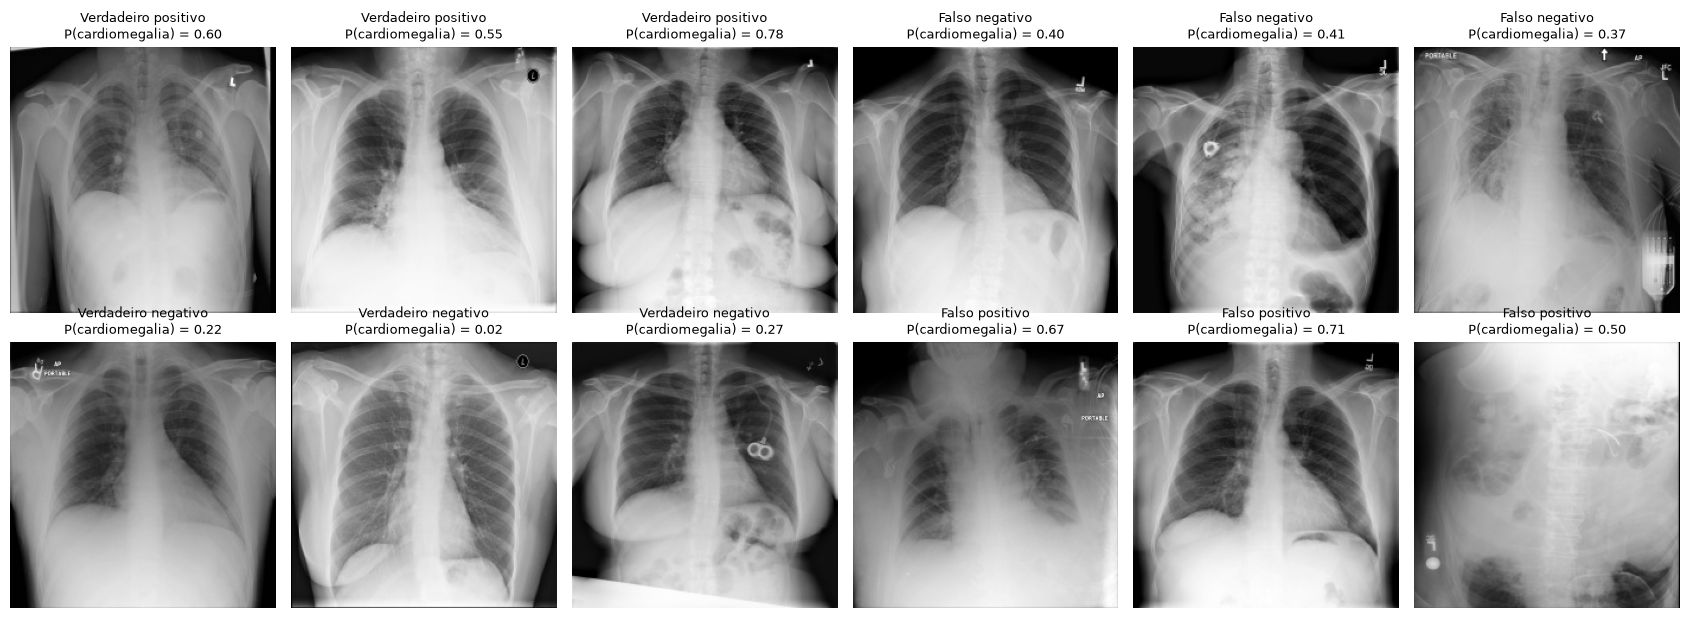

In [9]:
# Exemplos de acertos e erros no teste, para inspeção visual
arqs = np.array(teste.filepaths); yp = (p_test >= 0.5).astype(int)
grupos = [("Verdadeiro positivo", (y_test == 1) & (yp == 1)), ("Falso negativo", (y_test == 1) & (yp == 0)),
          ("Verdadeiro negativo", (y_test == 0) & (yp == 0)), ("Falso positivo", (y_test == 0) & (yp == 1))]
rng = np.random.default_rng(SEED)
fig, ax = plt.subplots(2, 6, figsize=(17, 6.2)); ax = ax.ravel(); k = 0
for nome, masc in grupos:
    for i in rng.choice(np.where(masc)[0], 3, replace=False):
        ax[k].imshow(plt.imread(arqs[i]), cmap="gray"); ax[k].set_title(f"{nome}\nP(cardiomegalia) = {p_test[i]:.2f}", fontsize=9); ax[k].axis("off"); k += 1
plt.tight_layout(); plt.savefig(DIR_PRINT / "09_cnn_exemplos.png", dpi=110); plt.show()

In [10]:
# Registro dos resultados para a comparação com o Transfer Learning e para a análise de fairness
pd.DataFrame({"arquivo": [str(Path(a).relative_to(DIR_PROC)) for a in arqs], "y": y_test, "prob": p_test}).to_csv(RAIZ / "data" / "pred_teste_cnn_do_zero.csv", index=False)
pd.DataFrame({"arquivo": [str(Path(a).relative_to(DIR_PROC)) for a in val.filepaths], "y": y_val, "prob": p_val}).to_csv(RAIZ / "data" / "pred_val_cnn_do_zero.csv", index=False)
res = {"modelo": "cnn_do_zero", "parametros": int(modelo.count_params()), "epocas": int(len(h)), "melhor_epoca": melhor,
       "tempo_treino_min": round(tempo_treino / 60, 1), "teste_limiar_0.5": r05, "teste_limiar_sensivel": rs,
       "tensorflow": tf.__version__, "seed": SEED}
(RAIZ / "data" / "resultados_cnn_do_zero.json").write_text(json.dumps(res, indent=2, default=float))
print(json.dumps(res, indent=2, default=float))

{
  "modelo": "cnn_do_zero",
  "parametros": 3452353,
  "epocas": 40,
  "melhor_epoca": 39,
  "tempo_treino_min": 33.1,
  "teste_limiar_0.5": {
    "limiar": 0.5,
    "acuracia": 0.7985347985347986,
    "precisao": 0.7869249394673123,
    "recall": 0.8084577114427861,
    "f1": 0.7975460122699386,
    "especificidade": 0.7889688249400479,
    "auc": 0.874160373193982,
    "tn": 329,
    "fp": 88,
    "fn": 77,
    "tp": 325
  },
  "teste_limiar_sensivel": {
    "limiar": 0.36,
    "acuracia": 0.7936507936507936,
    "precisao": 0.7432150313152401,
    "recall": 0.8855721393034826,
    "f1": 0.8081725312145289,
    "especificidade": 0.7050359712230215,
    "auc": 0.874160373193982,
    "tn": 294,
    "fp": 123,
    "fn": 46,
    "tp": 356
  },
  "tensorflow": "2.21.0",
  "seed": 42
}


## 6. Análise dos resultados

Todos os números abaixo vêm da execução gravada neste notebook (819 imagens de teste, 652 pacientes não vistos no treino).

**Desempenho.** Com limiar 0,5 a CNN do zero atingiu acurácia de 79,9%, precisão de 78,7%, recall de 80,8%, F1-score de 79,8% e AUC de 0,874. A matriz de confusão mostra 325 verdadeiros positivos, 329 verdadeiros negativos, 88 falsos positivos e 77 falsos negativos. Os erros estão distribuídos de forma equilibrada entre as duas classes.

**Treino.** A rede tem 3,45 milhões de parâmetros e treinou por 40 épocas em 33,1 minutos, em CPU. As curvas de treino e validação caminham juntas (acurácia de 80,8% no treino e 78,8% na validação na melhor época), o que indica pouco overfitting, efeito do dropout e do aumento de dados. A melhor época foi a 39, de 40: o treino atingiu o limite de épocas antes de a parada antecipada atuar, portanto a rede ainda poderia ganhar um pouco com mais épocas. O ganho nas últimas épocas já era pequeno (AUC de validação entre 0,861 e 0,871 nas dez últimas).

**Falsos negativos.** Com limiar 0,5 a rede deixa passar 77 dos 402 casos de Cardiomegalia (19,2%). Para um uso em triagem esse é o erro mais grave. Com o limiar de 0,36, escolhido na validação para manter recall de pelo menos 90%, os falsos negativos no teste caem para 46 (recall de 88,6%), ao custo de os falsos positivos subirem de 88 para 123 (especificidade de 70,5%). O recall no teste ficou um pouco abaixo dos 90% obtidos na validação, variação esperada entre amostras diferentes. A acurácia quase não muda (79,4%), o que mostra por que ela sozinha não basta para escolher o ponto de operação.

**Limitações.** O resultado vale para um conjunto balanceado artificialmente (50% de positivos). Na prevalência real do dataset (menos de 3%), a precisão seria muito menor para o mesmo recall. Os rótulos vêm de mineração de texto dos laudos e têm ruído, o que impõe um teto ao desempenho mensurável. A rede também não informa onde olhou na imagem, de modo que não é possível afirmar que a decisão se baseia na silhueta cardíaca.

**Próximo passo.** O notebook `03_transfer_learning.ipynb` aplica a ResNet50 pré-treinada ao mesmo problema e compara as duas abordagens neste mesmo conjunto de teste.